# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Pranaja Adyatma Budiman | 5054251009 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    KFold,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OneHotEncoder,
    LabelEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

sns.set_theme(style="whitegrid")

# Import tambahan untuk clustering
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import skew
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_INIT = 10

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv("Live.csv")

print("Jumlah baris, kolom:", df.shape)
print("\nTipe data:")
print(df.dtypes)
print("\n5 baris pertama:")
display(df.head())
print("\nStatistik deskriptif:")
display(df.describe().T)
print("\nMissing value per kolom:")
print(df.isna().sum())
print("\nBaris duplikat (seluruh kolom):", df.duplicated().sum())
print("status_id duplikat:", df["status_id"].duplicated().sum())
print("\nKolom yang seluruhnya kosong:", df.columns[df.isna().all()].tolist())

Jumlah baris, kolom: (7050, 16)

Tipe data:
status_id             int64
status_type             str
status_published        str
num_reactions         int64
num_comments          int64
num_shares            int64
num_likes             int64
num_loves             int64
num_wows              int64
num_hahas             int64
num_sads              int64
num_angrys            int64
Column1             float64
Column2             float64
Column3             float64
Column4             float64
dtype: object

5 baris pertama:


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN



Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
status_id,7050.0,3525.500000,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
num_reactions,7050.0,230.117163,462.625309,0.0,17.00,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.00,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.00,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.00,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.00,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.00,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.00,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.00,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.00,0.0,0.00,31.0



Missing value per kolom:
status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

Baris duplikat (seluruh kolom): 0
status_id duplikat: 0

Kolom yang seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']


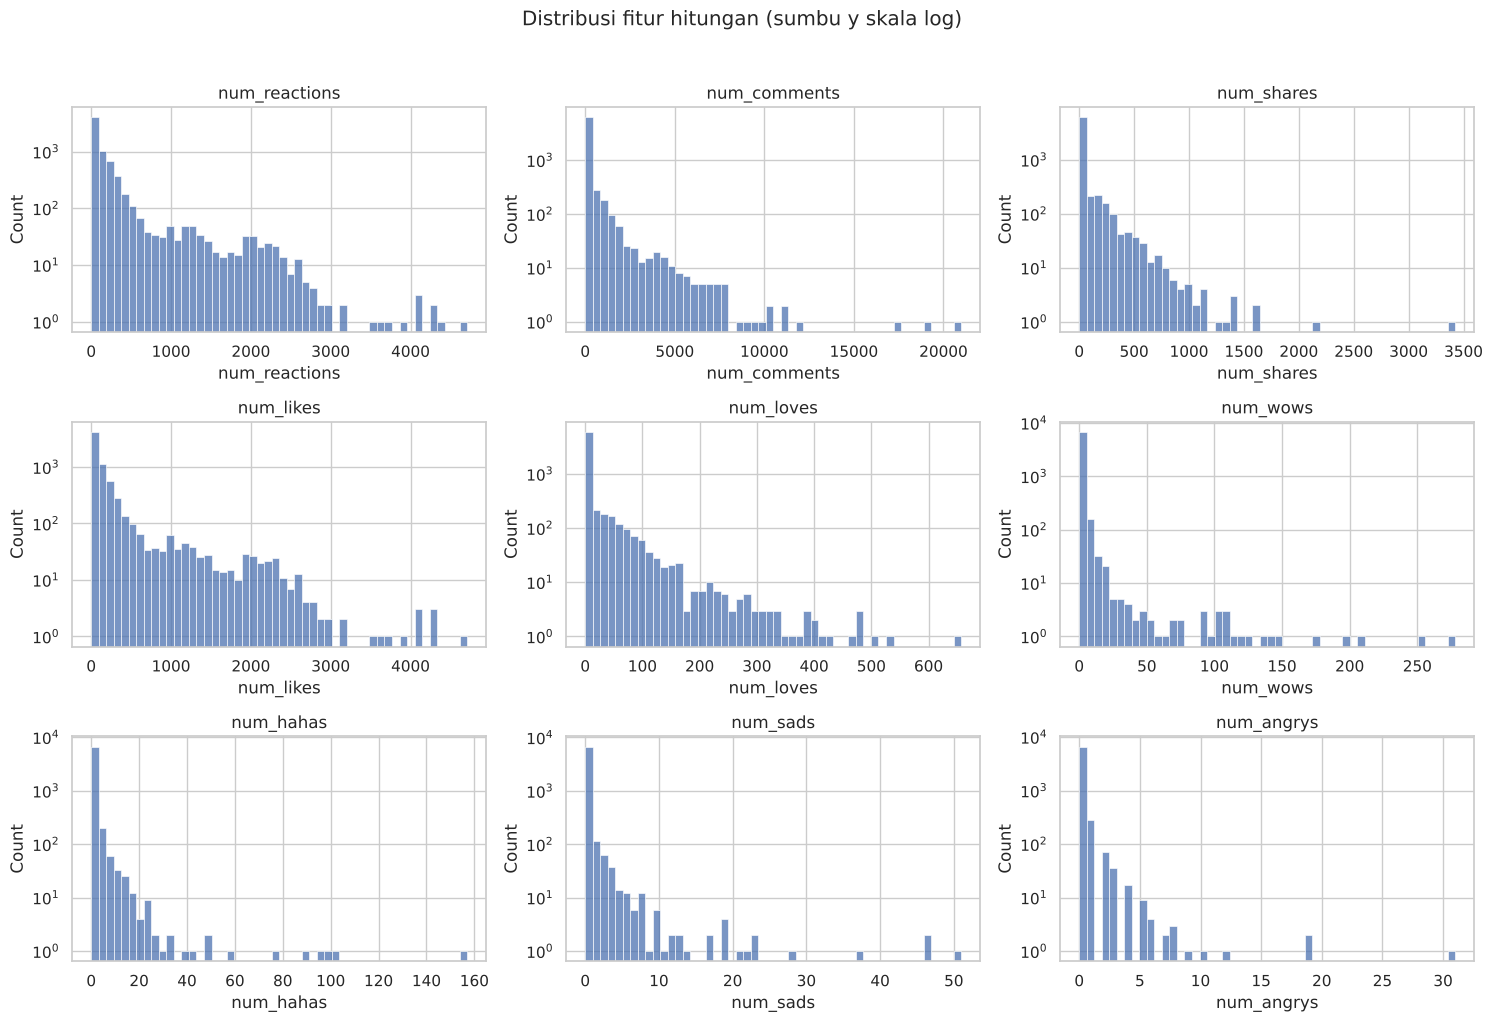

,skewness,proporsi_nol,median,mean,max
num_reactions,3.738,0.017,59.5,230.117,4710
num_comments,9.027,0.301,4.0,224.356,20990
num_shares,7.098,0.555,0.0,40.023,3424
num_likes,3.918,0.018,58.0,215.043,4710
num_loves,6.004,0.600,0.0,12.729,657
num_wows,18.243,0.753,0.0,1.289,278
num_hahas,20.301,0.839,0.0,0.696,157
num_sads,17.575,0.914,0.0,0.244,51
num_angrys,19.503,0.940,0.0,0.113,31


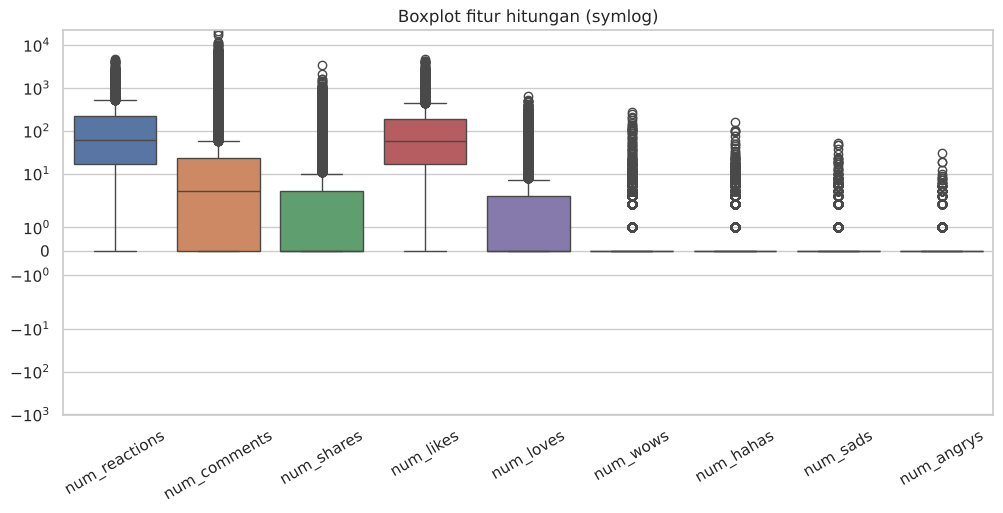

In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
count_cols = ["num_reactions", "num_comments", "num_shares", "num_likes", "num_loves",
              "num_wows", "num_hahas", "num_sads", "num_angrys"]

# Histogram tiap fitur hitungan
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), count_cols):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_yscale("log")
    ax.set_title(col)
plt.suptitle("Distribusi fitur hitungan (sumbu y skala log)", y=1.02)
plt.tight_layout()
plt.show()

# Ringkasan skewness, proporsi nol, dan skala
ringkas = pd.DataFrame({
    "skewness": df[count_cols].apply(skew),
    "proporsi_nol": (df[count_cols] == 0).mean(),
    "median": df[count_cols].median(),
    "mean": df[count_cols].mean(),
    "max": df[count_cols].max(),
}).round(3)
display(ringkas)

# Boxplot untuk melihat perbedaan skala antar fitur
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[count_cols])
plt.yscale("symlog")
plt.xticks(rotation=30)
plt.title("Boxplot fitur hitungan (symlog)")
plt.show()

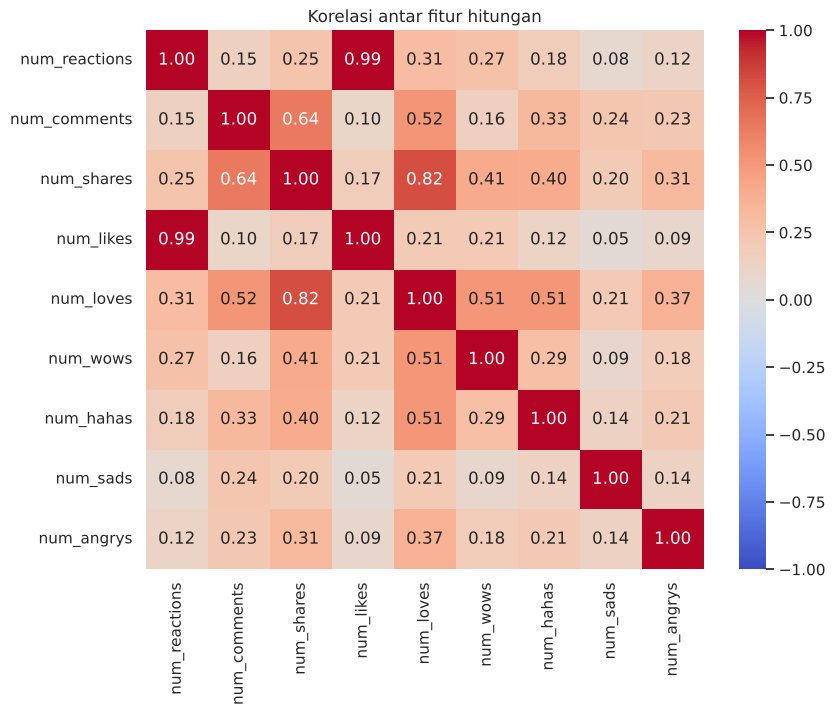

Selisih maksimum num_reactions vs jumlah 6 jenis reaksi: 4
Jumlah baris dengan selisih != 0: 9


In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(9, 7))
sns.heatmap(df[count_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi antar fitur hitungan")
plt.show()

# Cek redundansi secara definisi: num_reactions seharusnya = likes + loves + wows + hahas + sads + angrys
emoji_total = df[["num_likes", "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1)
selisih = (df["num_reactions"] - emoji_total).abs()
print("Selisih maksimum num_reactions vs jumlah 6 jenis reaksi:", selisih.max())
print("Jumlah baris dengan selisih != 0:", (selisih != 0).sum())

,jumlah_posting,proporsi_emoji
year,,
2012,589,0.000
2013,500,0.000
2014,233,0.000
2015,337,0.000
2016,588,0.680
2017,2253,0.542
2018,2550,0.578


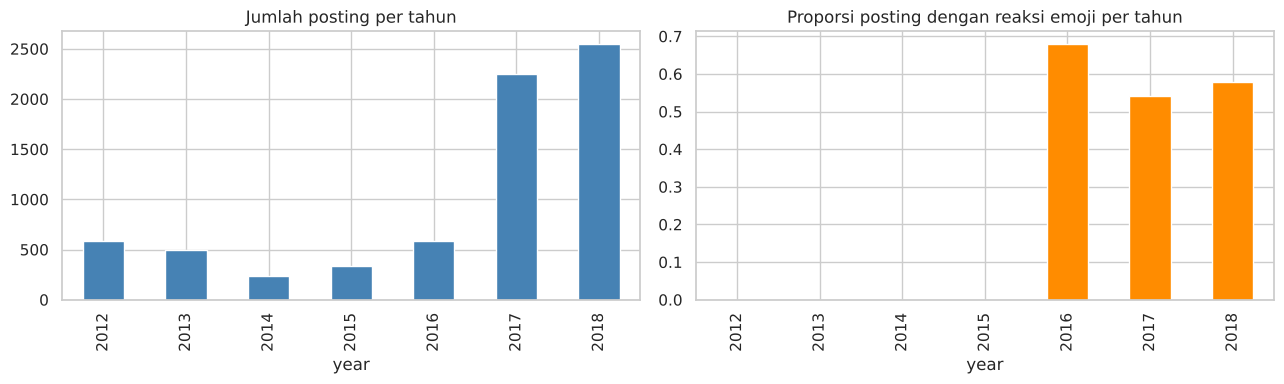

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df["status_published"] = pd.to_datetime(df["status_published"], format="%m/%d/%Y %H:%M")
df["year"] = df["status_published"].dt.year

# Posting dianggap punya reaksi emoji jika ada minimal satu love/wow/haha/sad/angry
df["has_emoji"] = (df[["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1) > 0)

per_tahun = df.groupby("year").agg(
    jumlah_posting=("status_id", "count"),
    proporsi_emoji=("has_emoji", "mean"),
).round(3)
display(per_tahun)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
per_tahun["jumlah_posting"].plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_title("Jumlah posting per tahun")
per_tahun["proporsi_emoji"].plot(kind="bar", ax=ax[1], color="darkorange")
ax[1].set_title("Proporsi posting dengan reaksi emoji per tahun")
plt.tight_layout()
plt.show()

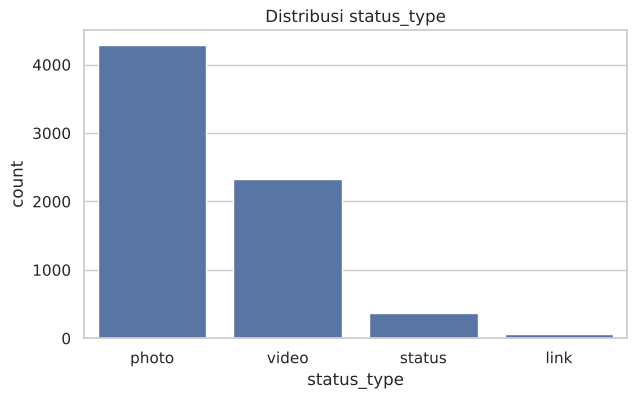

status_type
photo     0.608
video     0.331
status    0.052
link      0.009
Name: proportion, dtype: float64

Median engagement per status_type:


,num_likes,num_comments,num_shares
status_type,,,
link,48.0,1.0,0.0
photo,34.0,2.0,0.0
status,117.0,10.0,0.0
video,117.0,39.0,12.0


In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="status_type", order=df["status_type"].value_counts().index)
plt.title("Distribusi status_type")
plt.show()

print(df["status_type"].value_counts(normalize=True).round(3))
print("\nMedian engagement per status_type:")
display(df.groupby("status_type")[["num_likes", "num_comments", "num_shares"]].median())

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [7]:
# EDA tambahan 1: konsentrasi engagement (outlier ekstrem)
for col in ["num_comments", "num_shares", "num_likes"]:
    top1 = df[col].nlargest(int(len(df) * 0.01)).sum() / df[col].sum()
    print(f"{col}: 1% posting teratas menyumbang {top1:.1%} dari total")

print("\n10 posting dengan komentar terbanyak:")
display(df.nlargest(10, "num_comments")[["status_type", "status_published", "num_comments", "num_shares", "num_likes"]])

num_comments: 1% posting teratas menyumbang 30.9% dari total
num_shares: 1% posting teratas menyumbang 22.9% dari total
num_likes: 1% posting teratas menyumbang 12.8% dari total

10 posting dengan komentar terbanyak:


,status_type,status_published,num_comments,num_shares,num_likes
498,video,2016-11-30 08:46:00,20990,154,473
480,video,2016-12-09 21:48:00,19013,161,353
6757,video,2017-09-25 10:35:00,17404,913,525
3246,video,2018-01-08 01:10:00,12003,856,516
6762,video,2017-09-21 08:01:00,10960,783,540
6799,video,2017-09-09 10:05:00,10926,429,468
6659,photo,2017-11-24 02:23:00,10194,25,256
6448,video,2018-02-27 10:29:00,10186,793,336
6775,video,2017-09-16 10:00:00,9831,592,362
3892,video,2018-05-09 08:17:00,9452,1379,820


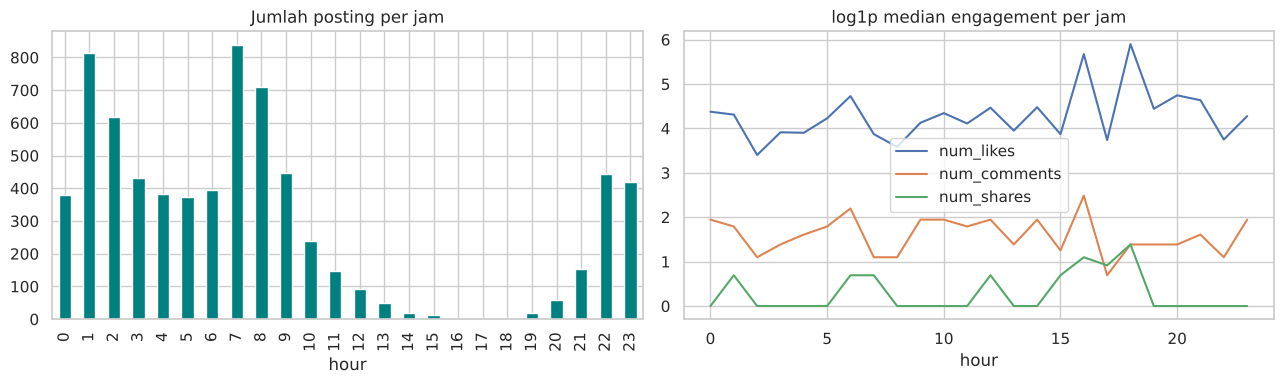

In [8]:
# EDA tambahan 2: jam posting dan engagement per jam
df["hour"] = df["status_published"].dt.hour
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["hour"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="teal")
ax[0].set_title("Jumlah posting per jam")
np.log1p(df.groupby("hour")[["num_likes", "num_comments", "num_shares"]].median()).plot(ax=ax[1])
ax[1].set_title("log1p median engagement per jam")
plt.tight_layout()
plt.show()
df = df.drop(columns=["hour"])

# 2. Preprocessing

In [9]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
# 1) Hapus kolom yang seluruhnya kosong (Column1 - Column4)
kolom_kosong = df.columns[df.isna().all()].tolist()
df = df.drop(columns=kolom_kosong)
print("Kolom dihapus:", kolom_kosong)

# 2) Duplikat
print("\nBaris duplikat penuh:", df.duplicated().sum())
cols_tanpa_id = [c for c in df.columns if c not in ["status_id", "status_published", "year", "has_emoji"]]
print("Baris dengan nilai engagement & tipe identik (abaikan status_id/waktu):", df.duplicated(subset=cols_tanpa_id).sum())
print("-> Tidak dihapus: status_id unik, jadi ini posting berbeda yang kebetulan punya angka sama (misal foto dengan like kecil dan sisanya 0).")

# 3) Missing value
print("\nMissing value tersisa:", df.isna().sum().sum())

# 4) Outlier ekstrem (aturan IQR)
rows = []
for col in ["num_comments", "num_shares", "num_likes", "num_loves"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    batas = q3 + 1.5 * (q3 - q1)
    rows.append({"fitur": col, "batas_atas_IQR": batas, "jumlah_outlier": (df[col] > batas).sum(),
                 "persen": round((df[col] > batas).mean() * 100, 1), "max": df[col].max()})
display(pd.DataFrame(rows))
print("Outlier tidak dibuang: itu posting viral yang sah dan bagian dari pola engagement. Dampaknya diredam dengan log1p.")

Kolom dihapus: ['Column1', 'Column2', 'Column3', 'Column4']

Baris duplikat penuh: 0
Baris dengan nilai engagement & tipe identik (abaikan status_id/waktu): 2063
-> Tidak dihapus: status_id unik, jadi ini posting berbeda yang kebetulan punya angka sama (misal foto dengan like kecil dan sisanya 0).

Missing value tersisa: 0


,fitur,batas_atas_IQR,jumlah_outlier,persen,max
0,num_comments,57.500,1374,19.5,20990
1,num_shares,10.000,1393,19.8,3424
2,num_likes,436.375,774,11.0,4710
3,num_loves,7.500,1323,18.8,657


Outlier tidak dibuang: itu posting viral yang sah dan bagian dari pola engagement. Dampaknya diredam dengan log1p.


In [10]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
# Pisahkan metadata untuk interpretasi (BUKAN fitur clustering)
meta = df[["status_type", "status_published"]].copy()

# Buang kolom yang tidak relevan untuk clustering
df_feat = df.drop(columns=["status_id", "status_type", "status_published", "year", "has_emoji"])

# Cek redundansi: num_reactions = jumlah semua jenis reaksi, jadi redundan
print("Korelasi num_reactions dengan num_likes:", round(df_feat["num_reactions"].corr(df_feat["num_likes"]), 4))

# Cek sparsity (proporsi nol)
print("\nProporsi nol per kolom:")
print((df_feat == 0).mean().round(3))

# Gabungkan reaksi emoji yang sangat sparse menjadi satu fitur
df_feat["num_other_reactions"] = df_feat[["num_wows", "num_hahas", "num_sads", "num_angrys"]].sum(axis=1)
print("\nProporsi nol num_other_reactions:", round((df_feat["num_other_reactions"] == 0).mean(), 3))

feature_cols = ["num_comments", "num_shares", "num_likes", "num_loves", "num_other_reactions"]
X = df_feat[feature_cols].copy()
print("\nFitur terpilih:", feature_cols)
print("Semua bertipe numerik:", all(np.issubdtype(t, np.number) for t in X.dtypes), "| bentuk X:", X.shape)

Korelasi num_reactions dengan num_likes: 0.9949

Proporsi nol per kolom:
num_reactions    0.017
num_comments     0.301
num_shares       0.555
num_likes        0.018
num_loves        0.600
num_wows         0.753
num_hahas        0.839
num_sads         0.914
num_angrys       0.940
dtype: float64

Proporsi nol num_other_reactions: 0.685

Fitur terpilih: ['num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_other_reactions']
Semua bertipe numerik: True | bentuk X: (7050, 5)


**Fitur yang dipilih untuk clustering:** `num_comments`, `num_shares`, `num_likes`, `num_loves`, dan `num_other_reactions` (= `num_wows` + `num_hahas` + `num_sads` + `num_angrys`).

Alasan dan keputusan:
- `num_reactions` **dibuang** karena redundan: nilainya hampir selalu sama dengan jumlah enam jenis reaksi (selisih hanya terjadi pada 9 baris, maksimum 4) dan korelasinya dengan `num_likes` 0,995. Jika dipertahankan, informasi "like" akan terhitung dua kali dalam jarak Euclidean.
- Reaksi emoji `wows`, `hahas`, `sads`, `angrys` sangat sparse (proporsi nol berturut-turut 75,3%, 83,9%, 91,4%, dan 94,0%), sehingga **digabung** menjadi `num_other_reactions` (proporsi nol turun menjadi 68,5%). Dengan begitu tidak ada empat dimensi yang hampir seluruhnya nol.
- `num_loves` (60% nol) tetap dipisah karena jumlahnya cukup besar dan maknanya berbeda (reaksi positif kuat).
- `status_id` dibuang (hanya pengenal), `status_type` dan `status_published` disimpan terpisah sebagai bahan interpretasi, bukan fitur.
- Catatan: reaksi emoji baru ada sejak 2016 (proporsi posting beserta emoji = 0 pada 2012-2015), jadi nol pada posting lama bisa berarti fitur belum tersedia, bukan tanpa minat.


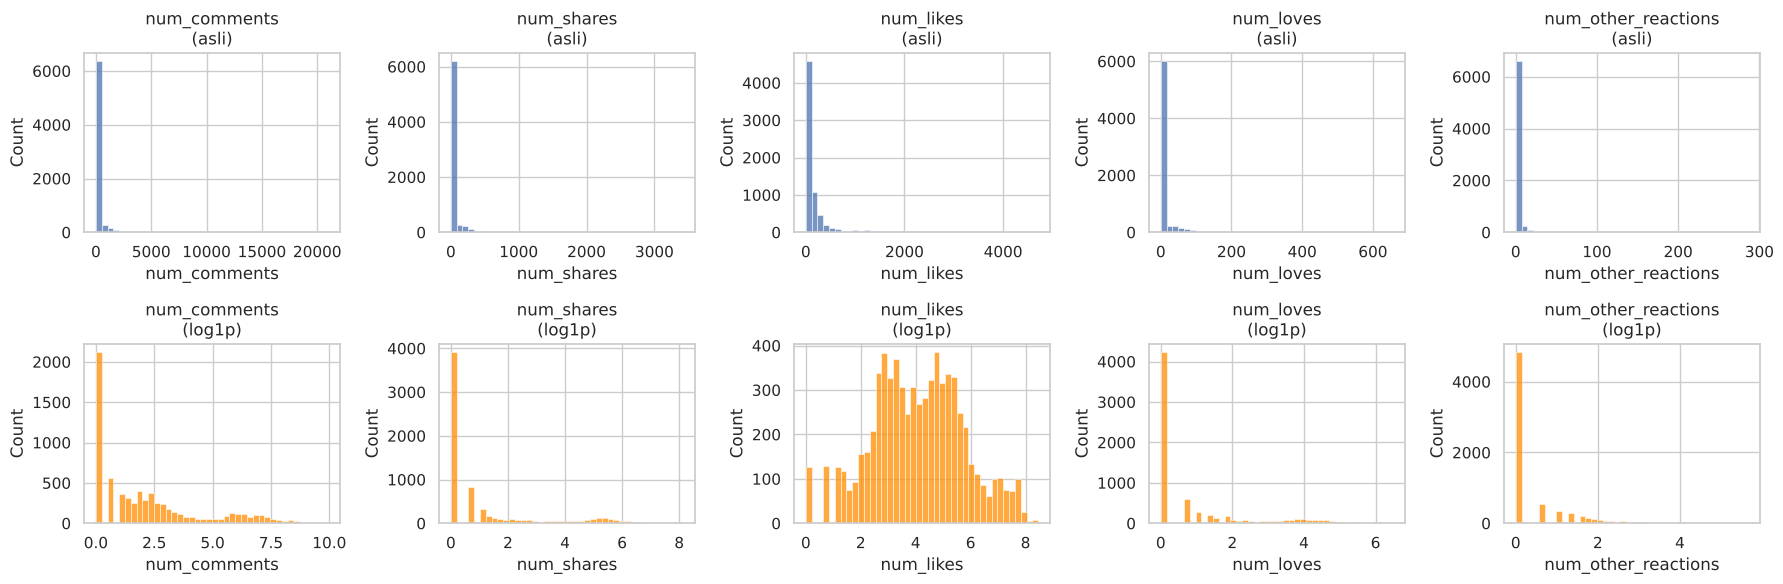

                     skew_sebelum  skew_sesudah
num_comments                 9.03          1.04
num_shares                   7.10          1.53
num_likes                    3.92         -0.01
num_loves                    6.00          1.50
num_other_reactions         13.88          1.94


In [11]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X)

fig, axes = plt.subplots(2, len(feature_cols), figsize=(18, 6))
for i, col in enumerate(feature_cols):
    sns.histplot(X[col], bins=40, ax=axes[0, i])
    axes[0, i].set_title(f"{col}\n(asli)")
    sns.histplot(X_log[col], bins=40, ax=axes[1, i], color="darkorange")
    axes[1, i].set_title(f"{col}\n(log1p)")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"skew_sebelum": X.apply(skew), "skew_sesudah": X_log.apply(skew)}).round(2))

In [12]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
# Versi 1: mentah tanpa transformasi dan tanpa scaling
X_raw = X.values

# Versi 2: mentah dengan scaling saja
X_raw_scaled = StandardScaler().fit_transform(X)

# Versi 3: log1p + scaling (dipakai untuk model utama)
X_log_scaled = StandardScaler().fit_transform(X_log)

print("X_raw:", X_raw.shape, "| X_raw_scaled:", X_raw_scaled.shape, "| X_log_scaled:", X_log_scaled.shape)
print("Mean X_log_scaled:", X_log_scaled.mean(axis=0).round(3), "| Std:", X_log_scaled.std(axis=0).round(3))

X_raw: (7050, 5) | X_raw_scaled: (7050, 5) | X_log_scaled: (7050, 5)
Mean X_log_scaled: [ 0. -0. -0.  0.  0.] | Std: [1. 1. 1. 1. 1.]


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [13]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
K_COMPARE = 3
versions = {"X_raw": X_raw, "X_raw_scaled": X_raw_scaled, "X_log_scaled": X_log_scaled}
labels_versions = {}
for name, data in versions.items():
    km = KMeans(n_clusters=K_COMPARE, random_state=RANDOM_STATE, n_init=N_INIT)
    labels_versions[name] = km.fit_predict(data)
    print(name, "-> ukuran cluster:", np.bincount(labels_versions[name]))

X_raw -> ukuran cluster: [6430  137  483]
X_raw_scaled -> ukuran cluster: [6368  292  390]
X_log_scaled -> ukuran cluster: [3654 1168 2228]


In [14]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
# Silhouette pada ruang yang sama (X_log_scaled) agar adil
hasil = []
for name, lab in labels_versions.items():
    ukuran = np.sort(np.bincount(lab))[::-1]
    hasil.append({"data_latih": name, "ukuran_cluster": ukuran.tolist(),
                  "persen_cluster_terbesar": round(ukuran[0] / len(lab) * 100, 1),
                  "silhouette (di X_log_scaled)": round(silhouette_score(X_log_scaled, lab), 4)})
display(pd.DataFrame(hasil))

# Fitur yang mendominasi varians pada data tanpa scaling
var = X.var()
print("\nVarians tiap fitur (data mentah):")
print(var.round(1))
print("\nKontribusi varians (%):")
print((var / var.sum() * 100).round(2))

,data_latih,ukuran_cluster,persen_cluster_terbesar,silhouette (di X_log_scaled)
0,X_raw,"[6430, 483, 137]",91.2,0.2967
1,X_raw_scaled,"[6368, 390, 292]",90.3,0.2462
2,X_log_scaled,"[3654, 2228, 1168]",51.8,0.4304



Varians tiap fitur (data mentah):
num_comments           791453.7
num_shares              17318.6
num_likes              202025.4
num_loves                1597.8
num_other_reactions       122.7
dtype: float64

Kontribusi varians (%):
num_comments           78.17
num_shares              1.71
num_likes              19.95
num_loves               0.16
num_other_reactions     0.01
dtype: float64


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [15]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
k_range = range(2, 11)
inertias = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_log_scaled)
    inertias.append(km.inertia_)
pd.DataFrame({"k": list(k_range), "inertia": np.round(inertias, 1)})

,k,inertia
0,2,15240.5
1,3,10302.5
2,4,8539.7
3,5,7468.3
4,6,6465.9
5,7,5843.5
6,8,5369.2
7,9,4941.2
8,10,4642.2


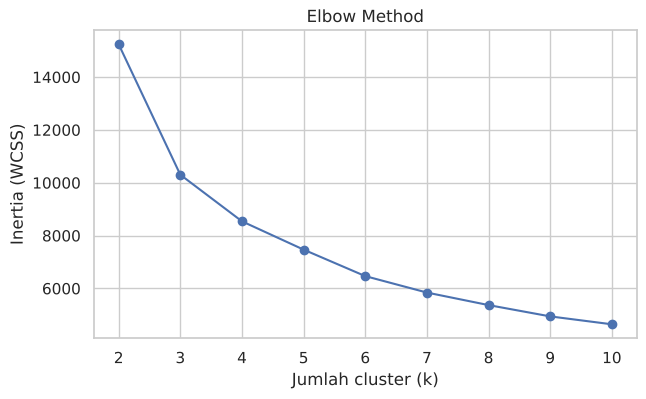

Elbow terdeteksi otomatis (kneed) di k = 4
Penurunan inertia antar k: [4938.  1762.9 1071.4 1002.4  622.4  474.3  428.   299.1]


In [16]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(7, 4))
plt.plot(list(k_range), inertias, marker="o")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method")
plt.xticks(list(k_range))
plt.show()

try:
    from kneed import KneeLocator
    kl = KneeLocator(list(k_range), inertias, curve="convex", direction="decreasing")
    print("Elbow terdeteksi otomatis (kneed) di k =", kl.elbow)
except ImportError:
    print("Library kneed belum terpasang (pip install kneed); lewati deteksi otomatis.")

print("Penurunan inertia antar k:", np.round(-np.diff(inertias), 1))

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [17]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
sil_scores = {}
for k in k_range:
    lab = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(X_log_scaled)
    sil_scores[k] = silhouette_score(X_log_scaled, lab)
pd.Series(sil_scores, name="silhouette").round(4)

2     0.5826
3     0.4304
4     0.4100
5     0.3962
6     0.3021
7     0.3090
8     0.3085
9     0.3016
10    0.2962
Name: silhouette, dtype: float64

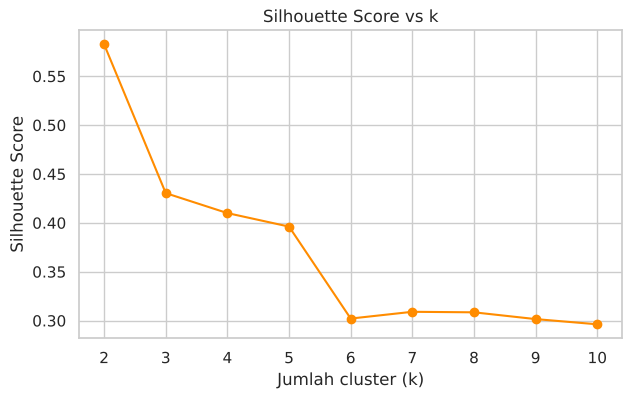

k terbaik menurut Silhouette: 2 | skor: 0.5826
k terbaik untuk k >= 3: 3 | skor: 0.4304


In [18]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(7, 4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o", color="darkorange")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs k")
plt.xticks(list(k_range))
plt.show()

k_sil = max(sil_scores, key=sil_scores.get)
print("k terbaik menurut Silhouette:", k_sil, "| skor:", round(sil_scores[k_sil], 4))
k_lain = {k: v for k, v in sil_scores.items() if k >= 3}
print("k terbaik untuk k >= 3:", max(k_lain, key=k_lain.get), "| skor:", round(max(k_lain.values()), 4))

**Pilihan k untuk K-Means:** **k = 3**.

- *Elbow Method*: penurunan inertia paling tajam terjadi dari k=2 ke k=3 (sekitar 4.938), lalu melandai (1.763 dari k=3 ke 4, dan seterusnya). `kneed` mendeteksi siku di k=4, sedangkan pengamatan visual menunjukkan siku di sekitar k=3-4.
- *Silhouette*: tertinggi di k=2 (0,583), tetapi k=2 terlalu kasar untuk membedakan profil engagement. Di antara k >= 3, k=3 terbaik (0,430), lalu k=4 (0,410), dan skor turun tajam setelah k=5.
- Karena itu k=3 dipilih sebagai kompromi: berada di rentang siku, silhouette tertinggi untuk k >= 3, dan menghasilkan tiga profil yang mudah ditafsirkan (sepi, menengah, viral).


## 3.4 Model K-Means Final

In [19]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
BEST_K = 3

def reorder_labels(labels):
    # Urutkan label cluster dari engagement terendah ke tertinggi agar mudah dibaca
    skor = pd.Series(X_log_scaled.sum(axis=1)).groupby(labels).mean().sort_values()
    peta = {lama: baru for baru, lama in enumerate(skor.index)}
    return np.array([peta[l] for l in labels])

km_final = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=N_INIT).fit(X_log_scaled)
labels_km = reorder_labels(km_final.labels_)
print("Ukuran cluster K-Means:", np.bincount(labels_km))

Ukuran cluster K-Means: [3654 2228 1168]


In [20]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
def profil_cluster(labels):
    data = X.assign(cluster=labels)
    out = data.groupby("cluster").median().round(1)
    out.columns = [c + " (median)" for c in out.columns]
    rata = data.groupby("cluster").mean().round(1)
    rata.columns = [c + " (mean)" for c in rata.columns]
    n = data.groupby("cluster").size().rename("jumlah")
    out = pd.concat([n, (n / n.sum() * 100).round(1).rename("persen"), out, rata], axis=1)
    return out

profil_km = profil_cluster(labels_km)
display(profil_km.T)

cluster,0,1,2
jumlah,3654.0,2228.0,1168.0
persen,51.8,31.6,16.6
num_comments (median),0.0,11.0,677.0
num_shares (median),0.0,1.0,169.5
num_likes (median),18.0,206.0,179.5
num_loves (median),0.0,1.0,50.0
num_other_reactions (median),0.0,0.0,5.0
num_comments (mean),2.2,28.0,1293.9
num_shares (mean),0.5,5.0,230.3
num_likes (mean),23.1,459.7,349.0


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [21]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
Z = linkage(X_log_scaled, method="ward")
print("Bentuk linkage matrix:", Z.shape)
print("Tinggi 6 penggabungan terakhir:", np.round(Z[-6:, 2], 2))

Bentuk linkage matrix: (7049, 4)
Tinggi 6 penggabungan terakhir: [ 41.48  44.26  51.59  74.64  93.25 191.2 ]


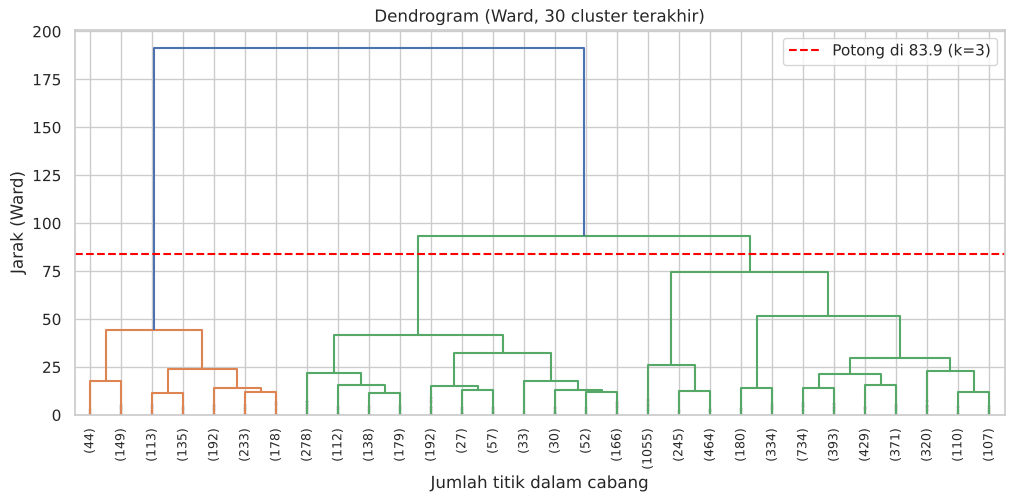

In [22]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
# Ambang potong untuk BEST_K cluster: di antara tinggi penggabungan ke-(k-1) dan ke-k dari akhir
potong = (Z[-(BEST_K - 1), 2] + Z[-BEST_K, 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.axhline(potong, color="red", linestyle="--", label=f"Potong di {potong:.1f} (k={BEST_K})")
plt.title("Dendrogram (Ward, 30 cluster terakhir)")
plt.xlabel("Jumlah titik dalam cabang")
plt.ylabel("Jarak (Ward)")
plt.legend()
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [23]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkages = ["ward", "complete", "average", "single"]
labels_link = {}
for lk in linkages:
    agg = AgglomerativeClustering(n_clusters=BEST_K, linkage=lk)
    labels_link[lk] = agg.fit_predict(X_log_scaled)
    print(lk, "-> ukuran cluster:", np.bincount(labels_link[lk]))

ward -> ukuran cluster: [4742 1044 1264]


complete -> ukuran cluster: [1374  200 5476]


average -> ukuran cluster: [1122 5899   29]
single -> ukuran cluster: [7048    1    1]


In [24]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
baris = []
for lk, lab in labels_link.items():
    ukuran = np.sort(np.bincount(lab))[::-1]
    baris.append({"linkage": lk, "silhouette": round(silhouette_score(X_log_scaled, lab), 4),
                  "ukuran_cluster": ukuran.tolist(),
                  "persen_terbesar": round(ukuran[0] / len(lab) * 100, 1),
                  "cluster_terkecil": int(ukuran[-1])})
tabel_linkage = pd.DataFrame(baris).set_index("linkage")
display(tabel_linkage)

,silhouette,ukuran_cluster,persen_terbesar,cluster_terkecil
linkage,,,,
ward,0.4001,"[4742, 1264, 1044]",67.3,1044
complete,0.4986,"[5476, 1374, 200]",77.7,200
average,0.5504,"[5899, 1122, 29]",83.7,29
single,0.3486,"[7048, 1, 1]",100.0,1


**Pilihan linkage untuk Hierarchical Clustering:** **Ward**.

Average (0,550) dan complete (0,499) memang memiliki silhouette lebih tinggi, tetapi skor itu muncul karena cluster yang sangat tidak seimbang (average menyisakan cluster berisi 29 titik, complete 200 titik). Single linkage paling buruk: 7.048 titik masuk satu cluster, sisanya hanya 1 titik per cluster. Ward menghasilkan cluster yang paling seimbang (4.742 / 1.264 / 1.044), dengan silhouette 0,400 dan pola yang sejalan dengan K-Means (keduanya meminimalkan varians dalam cluster), sehingga perbandingan kedua metode lebih adil dan hasilnya lebih berguna sebagai segmentasi.


## 4.3 Model Hierarchical Clustering Final

In [25]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
LINKAGE_FINAL = "ward"
hc_final = AgglomerativeClustering(n_clusters=BEST_K, linkage=LINKAGE_FINAL)
labels_hc = reorder_labels(hc_final.fit_predict(X_log_scaled))
print("Ukuran cluster Hierarchical:", np.bincount(labels_hc))

Ukuran cluster Hierarchical: [4742 1264 1044]


In [26]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
profil_hc = profil_cluster(labels_hc)
display(profil_hc.T)

cluster,0,1,2
jumlah,4742.0,1264.0,1044.0
persen,67.3,17.9,14.8
num_comments (median),1.0,12.0,809.5
num_shares (median),0.0,1.0,192.5
num_likes (median),26.0,169.5,166.5
num_loves (median),0.0,3.0,55.0
num_other_reactions (median),0.0,2.0,4.0
num_comments (mean),5.8,50.3,1427.9
num_shares (mean),1.2,8.4,254.5
num_likes (mean),170.2,331.7,277.4


# 5. Evaluasi Model

In [27]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
def metrik(labels):
    return {"Silhouette (naik lebih baik)": silhouette_score(X_log_scaled, labels),
            "Davies-Bouldin (turun lebih baik)": davies_bouldin_score(X_log_scaled, labels),
            "Calinski-Harabasz (naik lebih baik)": calinski_harabasz_score(X_log_scaled, labels)}

tabel_metrik = pd.DataFrame({"K-Means": metrik(labels_km), f"Hierarchical ({LINKAGE_FINAL})": metrik(labels_hc)}).round(4)
display(tabel_metrik)

print("Adjusted Rand Index K-Means vs Hierarchical:", round(adjusted_rand_score(labels_km, labels_hc), 4))
print("\nCrosstab label K-Means (baris) vs Hierarchical (kolom):")
display(pd.crosstab(labels_km, labels_hc, rownames=["KMeans"], colnames=["HC"]))

,K-Means,Hierarchical (ward)
Silhouette (naik lebih baik),0.4304,0.4001
Davies-Bouldin (turun lebih baik),0.9572,1.0866
Calinski-Harabasz (naik lebih baik),8532.1057,6315.4928


Adjusted Rand Index K-Means vs Hierarchical: 0.4821

Crosstab label K-Means (baris) vs Hierarchical (kolom):


HC,0,1,2
KMeans,,,
0,3515,139,0
1,1227,998,3
2,0,127,1041


Varians dijelaskan PC1: 73.1%, PC2: 13.2%, total: 86.3%


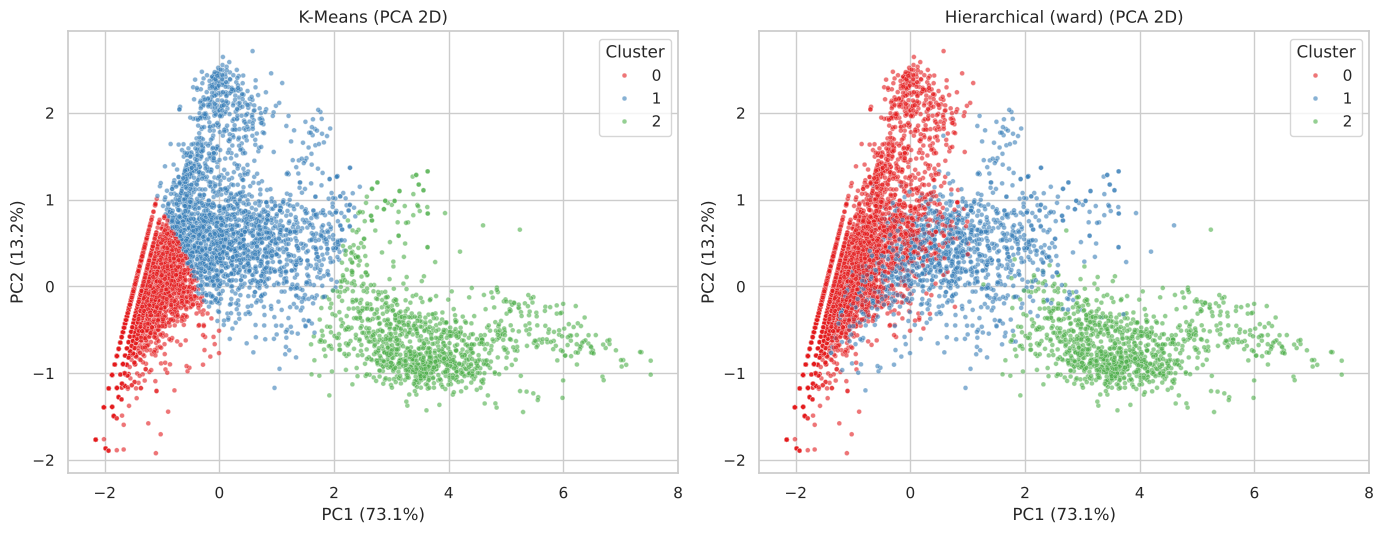

In [28]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)
print("Varians dijelaskan PC1: {:.1%}, PC2: {:.1%}, total: {:.1%}".format(
    pca.explained_variance_ratio_[0], pca.explained_variance_ratio_[1], pca.explained_variance_ratio_.sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, lab, judul in zip(axes, [labels_km, labels_hc], ["K-Means", f"Hierarchical ({LINKAGE_FINAL})"]):
    sc = sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=lab, palette="Set1", s=12, alpha=0.6, ax=ax)
    ax.set_title(f"{judul} (PCA 2D)")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    ax.legend(title="Cluster")
plt.tight_layout()
plt.show()

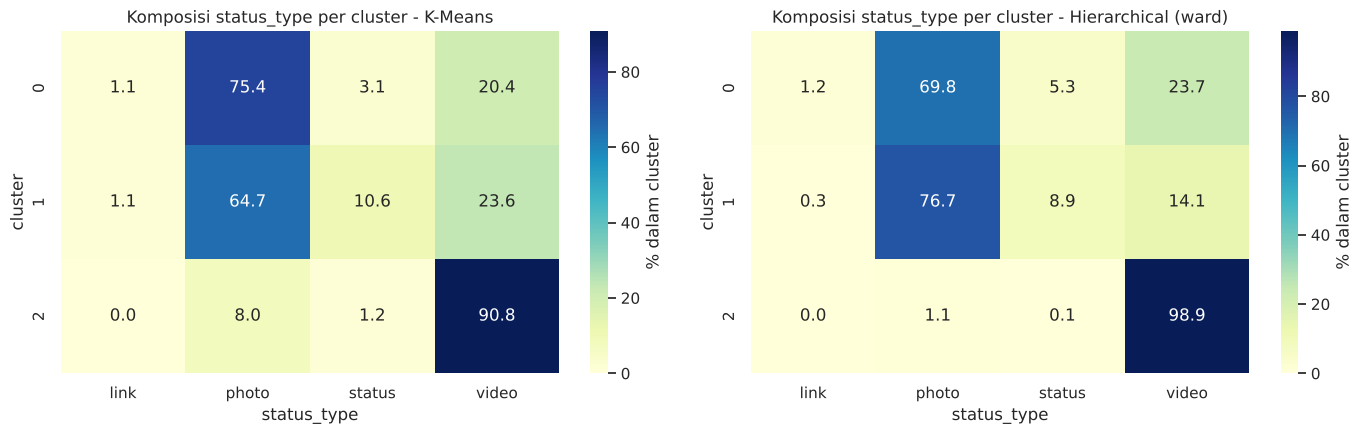

In [29]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, lab, judul in zip(axes, [labels_km, labels_hc], ["K-Means", f"Hierarchical ({LINKAGE_FINAL})"]):
    ct = pd.crosstab(lab, meta["status_type"].values, normalize="index") * 100
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "% dalam cluster"})
    ax.set_title(f"Komposisi status_type per cluster - {judul}")
    ax.set_xlabel("status_type")
    ax.set_ylabel("cluster")
plt.tight_layout()
plt.show()

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

## Jawaban Analisis

**1. Pengaruh log dan scaling pada K-Means (bagian 3.1).** Pada k=3, K-Means di `X_raw` menghasilkan cluster berukuran 6.430 / 483 / 137, atau 91,2% data masuk satu cluster. Penyebabnya, tanpa scaling `num_comments` menyumbang 78,2% dan `num_likes` 19,9% dari total varians, sedangkan `num_shares`, `num_loves`, dan `num_other_reactions` hampir tidak berpengaruh (kurang dari 2%). Jarak Euclidean praktis hanya ditentukan oleh komentar dan like, dan cluster kecil terbentuk dari beberapa posting ekstrem. Scaling saja (`X_raw_scaled`) tidak menyelesaikan masalah: cluster terbesar masih 90,3% dan silhouette (diukur di ruang `X_log_scaled`) malah turun menjadi 0,246, karena ekor distribusi yang sangat panjang (skewness komentar 9,0, share 7,1) membuat outlier tetap menarik centroid. Kombinasi log1p + scaling menurunkan skewness (misalnya komentar 9,03 menjadi 1,04) dan menyamakan skala, sehingga ukuran cluster jauh lebih seimbang (3.654 / 2.228 / 1.168) dan silhouette naik menjadi 0,430. Pada algoritma berbasis jarak, log menekan pengaruh outlier dan scaling menyamakan kontribusi tiap fitur; keduanya diperlukan, bukan salah satu.

**2. Kolom redundan dan banyak nol.** `num_reactions` dibuang karena merupakan jumlah dari reaksi lain (korelasi 0,995 dengan likes). Empat reaksi emoji yang sangat sparse (75-94% nol) digabung menjadi `num_other_reactions`, sedangkan `num_loves` dipertahankan. Kolom `Column1`-`Column4` seluruhnya kosong sehingga dihapus. Outlier tidak dibuang karena merupakan posting viral yang sah (1% posting teratas menyumbang 30,9% dari seluruh komentar); dampaknya diredam dengan log1p. Baris "duplikat" tanpa `status_id` (2.063 baris) tidak dihapus karena status_id unik dan tidak ada duplikat penuh.

**3. Jumlah cluster optimal.** Elbow menunjukkan siku di sekitar k=3-4 (`kneed`: k=4), sedangkan Silhouette tertinggi di k=2 (0,583) dan k=3 menjadi yang terbaik bila k=2 dikecualikan (0,430). Keduanya tidak sepenuhnya sepakat. Saya memilih k=3 karena k=2 terlalu kasar untuk interpretasi bisnis, sementara k=3 masih berada pada rentang siku dengan silhouette tertinggi untuk k >= 3.

**4. Perbandingan linkage (k=3).** Silhouette: average 0,550, complete 0,499, ward 0,400, single 0,349. Skor tinggi pada average dan complete menyesatkan karena cluster terkecilnya hanya 29 dan 200 titik (cluster terbesar 83,7% dan 77,7%). Single linkage menghasilkan satu cluster raksasa berisi 7.048 titik dan dua cluster berisi 1 titik: efek *chaining*, yaitu titik-titik digabung berantai lewat tetangga terdekat sehingga hanya outlier yang terpisah. Ward paling seimbang (4.742 / 1.264 / 1.044) sehingga dipilih. Pada dendrogram Ward, penggabungan terakhir terjadi pada jarak jauh lebih tinggi (191,2) dibanding sebelumnya (93,3 dan 74,6), yang mendukung pemotongan pada level k kecil.

**5. K-Means vs Hierarchical.** K-Means lebih baik pada ketiga metrik internal: Silhouette 0,430 vs 0,400, Davies-Bouldin 0,957 vs 1,087 (lebih rendah lebih baik), dan Calinski-Harabasz 8.532 vs 6.315. Hasilnya tidak identik (Adjusted Rand Index 0,482), tetapi perbedaannya terkonsentrasi pada batas cluster 0 dan 1: dari 2.228 posting di cluster 1 K-Means, 1.227 masuk cluster 0 pada Hierarchical. Cluster viral hampir sama (1.041 titik beririsan). Dua komponen PCA menjelaskan 86,3% varians (PC1 73,1%, PC2 13,2%), sehingga visualisasi 2D cukup representatif. Perbedaan terjadi karena data bersifat kontinu tanpa pemisahan alami yang tegas pada kelompok sepi-menengah; K-Means mengoptimalkan varians global secara iteratif dan bisa memindahkan titik antar cluster, sedangkan Ward bersifat greedy dan tidak bisa membatalkan penggabungan yang sudah dilakukan. Ukuran metrik internal juga cenderung menguntungkan K-Means karena kriterianya sama dengan yang dihitung metrik tersebut.

**6. Karakteristik cluster (K-Means, median fitur asli).**
- **Cluster 0 - "Posting Sepi"** (3.654 posting, 51,8%): median komentar 0, share 0, like 18, love 0; 75,4% foto. Hampir tanpa interaksi.
- **Cluster 1 - "Banyak Like, Sedikit Diskusi"** (2.228 posting, 31,6%): median like 206 tetapi komentar hanya 11 dan share 1; 64,7% foto dan memiliki porsi status tertinggi (10,6%). Dilihat dan disukai, tetapi jarang dikomentari atau dibagikan.
- **Cluster 2 - "Video Viral/Diskusi Ramai"** (1.168 posting, 16,6%): median komentar 677, share 169,5, love 50, reaksi lain 5; 90,8% video. Engagement aktif tertinggi.

Untuk Hierarchical (Ward): cluster 0 (4.742 posting, 67,3%) setara "Posting Sepi", cluster 1 (1.264 posting, 17,9%) setara "Banyak Like, Sedikit Diskusi" (komentar 12, share 1), dan cluster 2 (1.044 posting, 14,8%) setara "Video Viral" dengan 98,9% video. Catatan: status_type hanya untuk interpretasi, bukan label asli; cluster viral hampir seluruhnya video, sedangkan foto tersebar pada cluster sepi dan menengah.

**7. Kelebihan dan kekurangan.**
- *K-Means*: cepat dan hemat memori (skala dengan jumlah data dan k), mudah diterapkan pada data besar, dan menghasilkan centroid yang mudah diprofilkan. Kekurangannya: k harus ditentukan di awal, hasil bergantung inisialisasi (diatasi dengan `n_init`), mengasumsikan cluster berbentuk bulat dengan ukuran serupa, dan sensitif terhadap skala serta outlier.
- *Hierarchical*: tidak perlu menentukan k di awal (dendrogram bisa dipotong pada tinggi tertentu), deterministik, dan menunjukkan struktur bertingkat. Kekurangannya: membutuhkan waktu dan memori sekitar kuadratik terhadap jumlah data sehingga kurang cocok untuk data sangat besar (7.050 baris masih ringan), penggabungan tidak bisa dibatalkan, dan hasil sangat bergantung pada linkage (single rentan chaining, complete dan average rentan menyisakan cluster kecil).


# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

## Kesimpulan

- Transformasi log1p dan scaling terbukti krusial: tanpa keduanya K-Means menghasilkan satu cluster berisi sekitar 91% data yang didominasi komentar dan like; dengan keduanya, cluster seimbang dan silhouette naik dari 0,297 (mentah) menjadi 0,430.
- Fitur akhir terdiri dari 5 variabel (komentar, share, like, love, dan gabungan reaksi emoji lain) setelah membuang `num_reactions` yang redundan dan menggabungkan reaksi emoji yang sparse.
- k=3 dipilih berdasarkan Elbow (siku k=3-4) dan Silhouette (terbaik untuk k >= 3). Posting terbagi menjadi tiga profil: sepi, banyak like tetapi sedikit diskusi, dan viral (didominasi video).
- Untuk hierarchical clustering, Ward dipilih karena paling seimbang; average, complete, dan single memberi cluster sangat kecil atau chaining. K-Means sedikit lebih unggul pada ketiga metrik internal (Silhouette 0,430 vs 0,400; Davies-Bouldin 0,957 vs 1,087; Calinski-Harabasz 8.532 vs 6.315), dengan ARI 0,482; kedua metode sepakat pada cluster viral, dan berbeda terutama pada batas cluster sepi dan menengah.

**Saran:**
- Lakukan clustering terpisah untuk posting sebelum dan sesudah 2016, karena reaksi emoji baru tersedia mulai 2016 sehingga nol pada data lama bukan berarti tanpa minat.
- Manfaatkan fitur waktu (jam atau hari posting) serta rasio, misalnya komentar per like, untuk menangkap perilaku audiens yang lebih halus.
- Coba Gaussian Mixture Model atau DBSCAN karena batas cluster sepi-menengah tidak tegas, dan bandingkan dengan reduksi dimensi (PCA) sebelum clustering.
- Uji variasi hyperparameter K-Means (`n_init`, `init`) dan validasi stabilitas cluster dengan beberapa `random_state`.
- Validasi hasil dengan indikator bisnis (misalnya konversi penjualan) bila datanya tersedia, karena metrik internal tidak menjamin cluster bermakna secara praktis.
